In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.templates.default = "plotly_white"

netflix_red = '#E50914'
netflix_black = '#221F1F'

PALETTE = [netflix_red, netflix_black, '#b20710', '#F5A623', '#564d4d', '#FF6B6B', '#8B0000']
from plotly.offline import init_notebook_mode
init_notebook_mode(connected=True)
pio.renderers.default = "iframe"

# Problem statement

#### * This dataset tracks user engagement, hardware utilization, billing mechanisms, and account inactivity to help data scientists and analysts uncover:
#### *  Early Attrition Indicators: What behavioral signals (e.g., login inactivity, declining watch hours) predict churn before it happens?
#### *  Subscription Tier Viability: How do churn rates differ between Basic ($8.99), Standard ($13.99), and Premium ($17.99) plans?
#### *  Regional & Demographic Dynamics: Which geographic markets and age cohorts represent the highest retention or attrition risk?
#### *  Payment Gateway Friction: Does payment method (e.g., Crypto, Gift Card vs Credit/Debit) impact customer lifetime value?

## Data Profiling, Cleaning and Engineering

In [4]:
file = (r'C:\Users\DELL\Desktop\Programming\Data analytics\work\NetflixChurn\netflix_customer_churn.csv')


if os.path.exists(file):
    print("The file exist in the path, reading...")
    df = pd.read_csv(file)
    row, col = df.shape
    print("-------------------------------")
    print(f"Data frame's shape: Col {col}, Row {row}")
    print("-------------------------------")
    print(f'Duplicates: {df.duplicated().sum()}')
    print("-------------------------------")
    print(f'Null values: \n{df.isna().sum()}')
    print("-------------------------------")
    print(f'Objects type {df.dtypes}')
    print("-------------------------------")

else:
    print("The file does not exist in the path")

The file exist in the path, reading...
-------------------------------
Data frame's shape: Col 14, Row 5000
-------------------------------
Duplicates: 0
-------------------------------
Null values: 
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64
-------------------------------
Objects type customer_id                object
age                         int64
gender                     object
subscription_type          object
watch_hours               float64
last_login_days             int64
region                     object
device                     object
monthly_fee               float64
churned                     int64
payment_me

In [5]:
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [6]:
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


In [7]:
description_dis = df.groupby('subscription_type', as_index=False).agg({'customer_id':'count'})

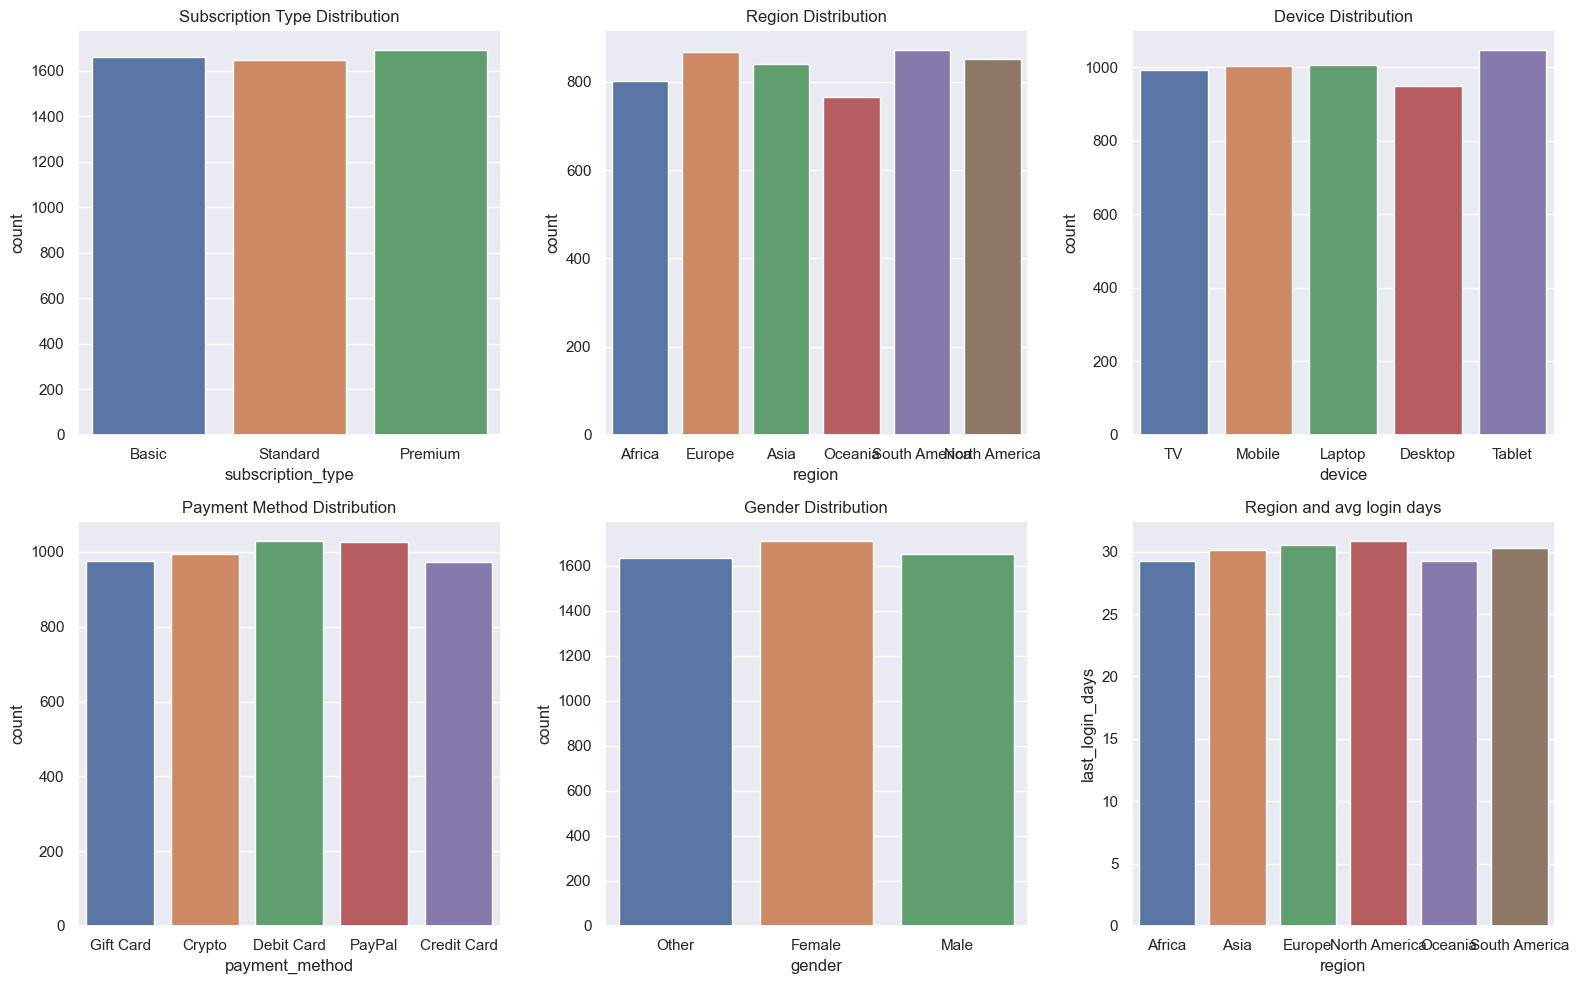

In [8]:
sns.set_theme(style='darkgrid')

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))

axes = axes.flatten()

sns.countplot(data=df, x='subscription_type', hue = 'subscription_type', ax=axes[0])
axes[0].set_title('Subscription Type Distribution')

sns.countplot(data=df, x='region', hue = 'region', ax=axes[1])
axes[1].set_title('Region Distribution')

sns.countplot(data=df, x='device', hue= 'device', ax=axes[2])
axes[2].set_title('Device Distribution')

sns.countplot(data=df, x='payment_method', hue='payment_method', ax=axes[3])
axes[3].set_title('Payment Method Distribution')

sns.countplot(data=df, x='gender', hue='gender', ax=axes[4])
axes[4].set_title('Gender Distribution')

avg_login_df = np.round(df.groupby('region', as_index=False).agg({'last_login_days':'mean'}), 2)
sns.barplot(data=avg_login_df, x='region', y='last_login_days',hue='region', ax=axes[5])
axes[5].set_title('Region and avg login days')


#fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

### 1. What is the average age of Netflix customers?

In [40]:
global_avg_age = np.round(df['age'].mean(),1)
global_median_age = df['age'].median()
global_avg_age

43.8

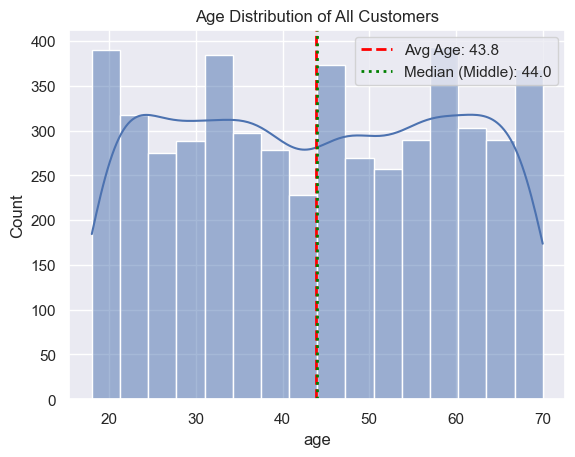

In [42]:
sns.histplot(data=df, x='age', kde=True)
plt.axvline(global_avg_age, color='red', linestyle='--', linewidth=2, label=f'Avg Age: {global_avg_age:.1f}')
plt.axvline(global_median_age, color='green', linestyle=':', linewidth=2, label=f'Median (Middle): {global_median_age:.1f}')
plt.title('Age Distribution of All Customers')
plt.legend();

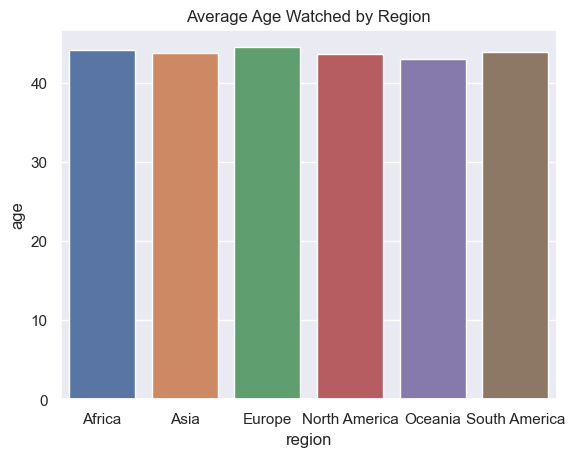

In [43]:
avg_age_region = np.round(df.groupby('region',as_index=False).agg({'age':'mean'}),1)
plt.title('Average Age Watched by Region')
sns.barplot(avg_age_region, x='region', y='age',hue='region');

### 2. What is the average number of watch hours?

In [47]:
global_avg_watched_hrs = np.round(df['watch_hours'].mean(),2)
global_median_watched_hrs = np.round(df['watch_hours'].median(),2)

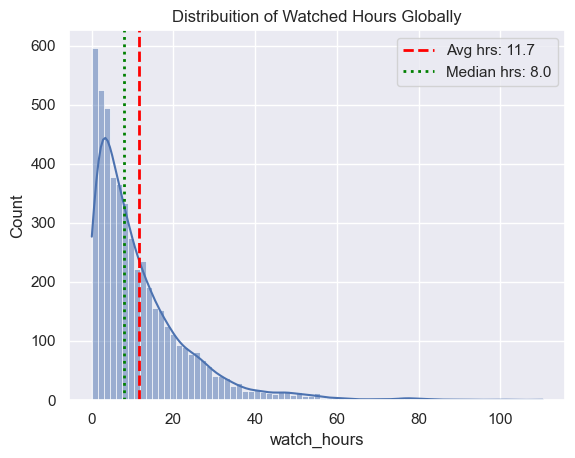

In [49]:
sns.histplot(data=df, x='watch_hours',kde=True)
plt.axvline(global_avg_watched_hrs, color='red', linestyle='--', linewidth=2, label=f'Avg hrs: {global_avg_watched_hrs:.1f}')
plt.axvline(global_median_watched_hrs, color='green', linestyle=':', linewidth=2, label=f'Median hrs: {global_median_watched_hrs:.1f}')
plt.title('Distribuition of Watched Hours Globally')
plt.legend()
plt.show()

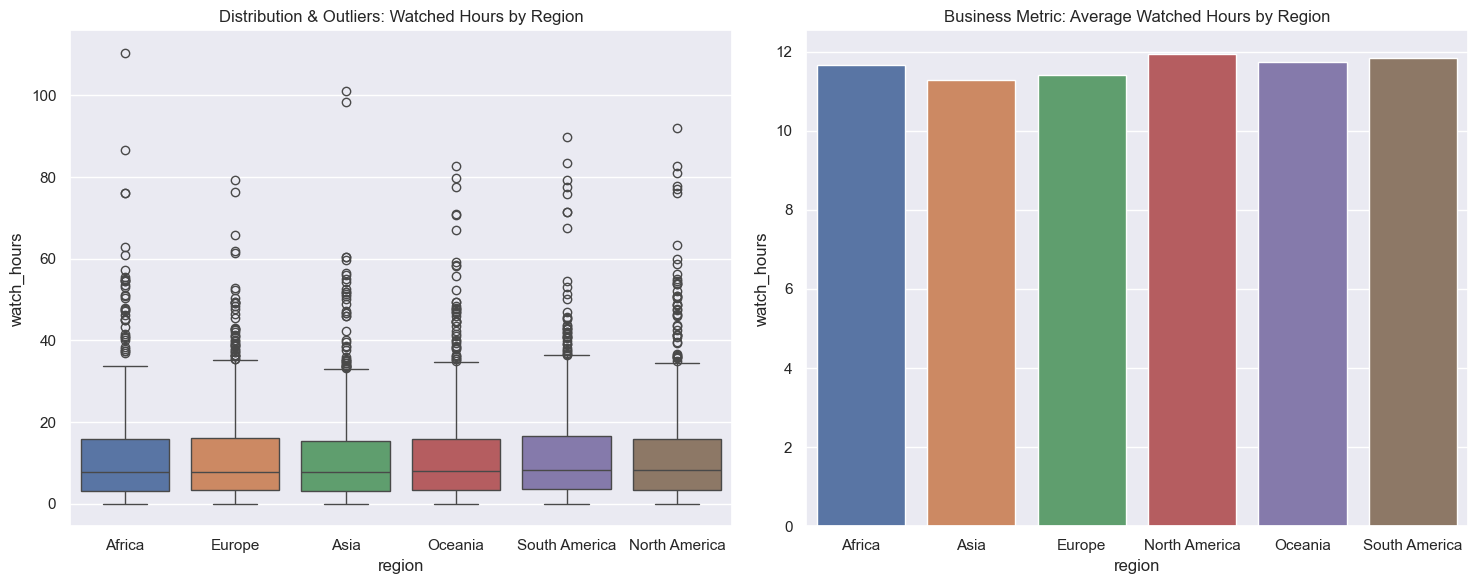

In [52]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# Left Chart: Boxplot (Shows the true distribution, median, and outliers per region)
sns.boxplot(data=df, x='region', y='watch_hours',hue='region', ax=axes[0])
axes[0].set_title('Distribution & Outliers: Watched Hours by Region')

# Right Chart: Barplot (Shows the simple average per region)
# Using estimator='mean' automatically calculates the average without needing groupby
avg_watched_hrs_region = round(df.groupby('region',as_index=True).agg({'watch_hours':'mean'}),2)
plt.title('Average Hours Watched by Region')
sns.barplot(avg_watched_hrs_region, x='region', y='watch_hours',hue='region');
axes[1].set_title('Business Metric: Average Watched Hours by Region')

plt.tight_layout()
plt.show()

### 3. Who are the top 10 customers with the highest watch hours?

In [56]:
top_customers = np.round(df.groupby('customer_id',as_index=False).agg({'watch_hours':'sum'}),2)

In [58]:
top_10 = df.nlargest(10, "watch_hours").copy()
top_10['Customer_Short'] = top_10['customer_id'].astype(str).str[:8]

In [59]:
top_10.head(5)

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,Customer_Short
3987,336a2ae7-f0bc-4aa5-8fc8-540c138b7d3c,70,Male,Basic,110.40,33,Africa,Desktop,8.99,0,PayPal,5,3.25,Horror,336a2ae7
4544,08645725-d1af-4d97-ab3d-2e4f806c7f82,67,Male,Basic,101.06,19,Asia,TV,8.99,0,Credit Card,2,5.05,Documentary,08645725
2017,23e2a122-9e50-41d8-a434-c25675765f79,42,Male,Basic,98.42,0,Asia,Desktop,8.99,0,Gift Card,5,98.42,Documentary,23e2a122
339,9d59350b-6bf3-48ad-aa59-d0fc92f66475,66,Other,Premium,92.07,58,North America,Mobile,17.99,0,PayPal,3,1.56,Comedy,9d59350b
3656,274599c6-5a23-4d2e-a471-22fa0e76e24e,51,Male,Basic,89.83,53,South America,Laptop,8.99,0,Gift Card,5,1.66,Drama,274599c6


In [60]:
fig = px.bar(
    top_10,
    x='watch_hours',
    y='Customer_Short', # استخدمنا العمود المختصر
    orientation='h',
    color='watch_hours',
    color_continuous_scale='Reds', # تدرج جاهز وبسيط
    title='Top 10 Customers by Watch Hours',
    text_auto='.1f' # إظهار الرقم على العمود بوضوح
)
fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    title_x=0.5,               # توسيط العنوان
    title_font_size=20,        # تكبير خط العنوان
    yaxis_title="",            # إخفاء كلمة Customer ID لمنع الزحمة
    xaxis_title="Watch Hours",
    template='plotly_white',   # ثيم فاتح ونظيف
    height=500,
    margin=dict(l=80)          # تظبيط الهامش الشمال
)

fig.show()

### Which region has the highest average watch time per day?

In [67]:
reg_daily = np.round(df.groupby('region',as_index=False).agg({'avg_watch_time_per_day':'mean'}),2)
fig = px.scatter(reg_daily, x='region', y='avg_watch_time_per_day', size='avg_watch_time_per_day',
                 color='region', color_discrete_sequence=px.colors.sequential.Reds_r,
                 title="Average Daily Watch Time by Region", size_max=40)
fig.update_layout(plot_bgcolor='rgba(0,0,0,0)')
fig.show()


In [78]:
reg_daily = np.round(df.groupby('device',as_index=False).agg({'avg_watch_time_per_day':'mean'}),2)
fig = px.scatter(reg_daily, x='device', y='avg_watch_time_per_day', size='avg_watch_time_per_day',
                 color='device', color_discrete_sequence=px.colors.sequential.Reds_r,
                 title="Average Daily Watch Time by Device", size_max=40)
fig.update_layout(plot_bgcolor='rgba(0,0,0,0)')
fig.show()

In [80]:
genre_watch = df.groupby("favorite_genre")['watch_hours'].mean().reset_index()
fig = px.treemap(genre_watch, path=[px.Constant("Genres"), 'favorite_genre'], values='watch_hours',
                 color='watch_hours', color_continuous_scale='Reds',
                 title="Average Watch Hours by Genre")
fig.show()

### What is the overall customer churn rate?

In [95]:
churn_rate = np.round(df['churned'].mean() * 100,2)

In [100]:
fig = go.Figure(go.Indicator(
    mode="gauge+number",
    value=churn_rate,
    number={'suffix': "%"},
    title={'text': "Overall Customer Churn Rate"},
    gauge={
        'axis': {'range': [0, 100]},
        'bar': {'color': netflix_red},
        'steps': [
            {'range': [0, 20], 'color': "lightgreen"},
            {'range': [20, 50], 'color': "yellow"},
            {'range': [50, 100], 'color': "lightcoral"}],
    }
))
fig.update_layout(margin=dict(b=80, t=60))
fig.show()

### Which subscription type has the highest churn rate?

In [165]:
sub_churn  = np.round((df.groupby('subscription_type')['churned'].mean() 
          *100).reset_index(),2)
fig = px.bar(
    sub_churn,
    x='churned',
    y='subscription_type',  # استخدمنا العمود المختصر
    orientation='h',
    color='churned',
    color_continuous_scale='Reds', # تدرج جاهز وبسيط
    title= "Churn Rate by Subscription Type (%)",
    text_auto='.1f' # إظهار الرقم على العمود بوضوح
)
fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    title_x=0.5,               # توسيط العنوان
    title_font_size=20,        # تكبير خط العنوان
    yaxis_title="",            # إخفاء كلمة Customer ID لمنع الزحمة
    xaxis_title="Churned customers",
    template='plotly_white',   # ثيم فاتح ونظيف
    height=500,
    margin=dict(l=80)          # تظبيط الهامش الشمال
)


In [210]:
reg_churn = np.round((df.groupby('region')['churned'].mean() * 100).reset_index(),2)
fig = px.bar(
    reg_churn,
    x='churned',
    y='region', # استخدمنا العمود المختصر
    orientation='h',
    color='churned',
    color_continuous_scale='Reds', # تدرج جاهز وبسيط
    title='Churn Rate By Region (%)',
    text_auto='.1f' # إظهار الرقم على العمود بوضوح
)
fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    title_x=0.5,               # توسيط العنوان
    title_font_size=20,        # تكبير خط العنوان
    yaxis_title="",            # إخفاء كلمة Customer ID لمنع الزحمة
    xaxis_title="churned %",
    template='plotly_white',   # ثيم فاتح ونظيف
    height=500,
    margin=dict(l=80)          # تظبيط الهامش الشمال
)

fig.show()

In [203]:
dev_churned = np.round((df.groupby('device')['churned'].mean() *100).reset_index())

In [207]:
dev_churned = np.round((df.groupby('device')['churned'].mean() *100).reset_index())
fig = px.scatter(dev_churned, x='device', y='churned', size='churned',
                 color='device', color_discrete_sequence=px.colors.sequential.Reds_r,
                 title="Churn Rate by Device (%)", size_max=40)
fig.update_layout(plot_bgcolor='rgba(0,0,0,0)')
fig.show()

In [212]:
reg_churn = np.round((df.groupby('payment_method')['churned'].mean() * 100).reset_index(),2)
reg_churn

,payment_method,churned
0,Credit Card,43.58
1,Crypto,59.70
2,Debit Card,43.69
3,Gift Card,57.79
4,PayPal,47.08


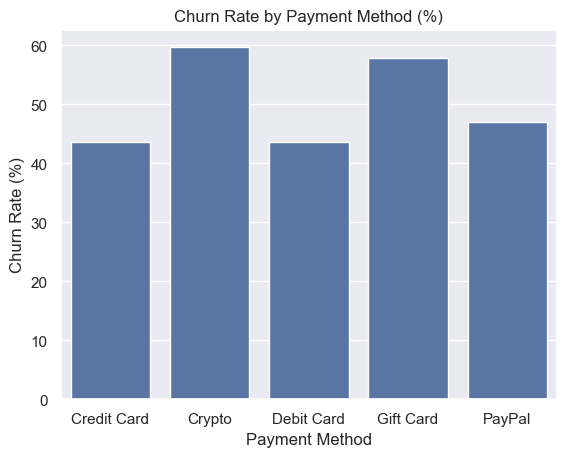

In [228]:
# 1. Your exact grouping math (Perfectly written)
# This creates a dataframe with 'payment_method' and 'churned' (as a %)
reg_churn = np.round((df.groupby('payment_method')['churned'].mean() * 100).reset_index(), 2)

# 2. Use a Barplot for categorical aggregated data
sns.barplot(data=reg_churn, x='payment_method', y='churned')

# 3. Update titles and labels to match the new context
plt.title('Churn Rate by Payment Method (%)')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Payment Method')

plt.show()

In [262]:
churn_count = df["churned"].value_counts().reset_index()
churn_count['rate%'] = churn_count['count'].apply(lambda x:(x/churn_count['count'].sum())*100)
churn_count

,churned,count,rate%
0,1,2515,50.3
1,0,2485,49.7


In [266]:
churn_count = df["churned"].value_counts().reset_index()
churn_count.columns = ['churned', 'count']
churn_count['Status'] = churn_count['churned'].map({0: 'Active', 1: 'Churned'})
fig = px.pie(churn_count, values='count', names='Status', hole=0.6,
             color_discrete_sequence=[netflix_black, netflix_red],
             title="Distribution of Active vs Churned Customers")
fig.update_traces(textposition='inside', textinfo='percent+label',
                  hoverinfo='label+percent+value', marker=dict(line=dict(color='#ffffff', width=1)))
fig.update_layout(annotations=[dict(text='Customers', x=0.5, y=0.5, font_size=17, showarrow=False)])
fig.show()


In [268]:
(df['churned'].value_counts(normalize=True) * 100).reset_index()

,churned,proportion
0,1,50.3
1,0,49.7
